# Documento de trabajo para regresion lineal

Descripcion del análsis: Escribe la descripcion y objetivo del análisis.

Justificación del modelo: Escribe la justificación de porque se eligió este modelo

Autor: Escribe tu nombre aquí

Fecha de creación: Escribe la fecha de creación (YYYY-MM-DD)

Fecha de última actualización: Escribe la fecha de creación (YYYY-MM-DD)

Descripcion del modelo: El modelo de regresión lineal se utiliza para analizar la relación entre una variable dependiente y una o más variables independientes, permitiendo estimar el efecto de las variables explicativas sobre la variable de interés. Este modelo asume que la relación entre las variables es lineal y que los errores son independientes y normalmente distribuidos con media cero y varianza constante.

In [ ]:
import os
from pyprojroot import here

os.chdir(here() / "src")
print("Nuevo directorio:", os.getcwd())

Nuevo directorio: c:\ABM\Analisis\Analisis_varios\src


In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera

from config import CAT_CONCEPTOS_PATH, CAT_INSTITUCIONES_PATH, SERIE_HISTORICA_PATH
from services.api_service import banxico_sie


## Lectura de datos

In [20]:
# Lectura de los archivos CSV y preparación de la serie histórica completa
serie_historica = pd.read_csv(SERIE_HISTORICA_PATH)
cat_conceptos = pd.read_csv(CAT_CONCEPTOS_PATH)
cat_instituciones = pd.read_csv(CAT_INSTITUCIONES_PATH)

serie_historica_completa = serie_historica.merge(cat_conceptos, on='idconcepto', how='left', suffixes=('', '_y'))
serie_historica_completa = serie_historica_completa.merge(cat_instituciones, on='entidad', how='left', suffixes=('', '_z'))
serie_historica_completa = serie_historica_completa.loc[:,~serie_historica_completa.columns.str.endswith(('_y', '_z'))]

serie_historica_completa["periodo"] = pd.to_datetime(
        serie_historica_completa["periodo"], format="%Y%m"
    )

# Sort the historical series by 'periodo', 'entidad', 'saldo', 'orden', and 'nivel'
serie_historica_completa = serie_historica_completa.sort_values(
    by=["periodo", "entidad", "saldo", "orden", "nivel"],
    ascending=[True, True, False, True, True],
)

serie_historica_completa.head()

C:\Users\djimenez\AppData\Local\Temp\ipykernel_15840\994844137.py:10: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  serie_historica_completa["periodo"] = pd.to_datetime(


,sector,idconcepto,entidad,periodo,saldo,valor,idtema,descripcion,nivel,indicador,orden,nombre_entidad,grupo,nombre_grupo
12179648,40,40100001,5,2000-12-01,133,2.031704e+12,1,Activo,1,0,1,Total Banca Múltiple,5,Total Banca Múltiple
12179662,40,40100045,5,2000-12-01,133,2.248958e+11,1,Efectivo y equivalentes de efectivo,2,0,2,Total Banca Múltiple,5,Total Banca Múltiple
12179663,40,40100046,5,2000-12-01,133,2.938613e+10,1,Caja,3,0,3,Total Banca Múltiple,5,Total Banca Múltiple
12179664,40,40100047,5,2000-12-01,133,1.761844e+11,1,Bancos,3,0,4,Total Banca Múltiple,5,Total Banca Múltiple
12179665,40,40100049,5,2000-12-01,133,0.000000e+00,1,Divisas a recibir,4,0,6,Total Banca Múltiple,5,Total Banca Múltiple


In [21]:
series_cnbv_id = {40100001: 'Activo_total',
                  40100186: 'Credito_comercial',
                  40100206: 'Credito_consumo',
                  40100217: 'Credito_vivienda',
                  40200017: 'IMOR',
                  40200018: 'IMOR_comercial',
                  40200019: 'IMOR_consumo',
                  40200020: 'IMOR_vivienda',
                  40200140: 'Tasa_implicita',
                  40200141: 'Tasa_impl_comercial',
                  40200145: 'Tasa_impl_consumo',
                  40200156: 'Tasa_impl_vivienda',
                  40200037: 'Tasa_impl_pasiva',
                  40100031: 'Reservas',
                  40100010: 'Comisiones_cobradas',
                  40100167: 'Comisiones_pagadas',
                  40100170: 'Ingresos_operativos',
                  40100011: 'Gastos_operativos',
                  40100009: 'Margen_financiero_ajustado_riesgo',
                  40200218: 'Margen_intermediacion',
                  40100013: 'Resultado_neto',
                  40200002: 'ROE',
                  }

In [ ]:
# Obtenemos todas las series de interés de la serie histórica completa
series_cnbv = serie_historica_completa[serie_historica_completa['idconcepto'].isin(list(series_cnbv_id.keys()))]

# Filtramos por entidad (Total banca multiple)
series_cnbv = series_cnbv[series_cnbv['entidad'] == 5]

# Filtramos por tipo de saldo ( consolidado)
series_cnbv = series_cnbv[series_cnbv['saldo'] == 133]

# Pivotamos la tabla y dejamos la descripcion como el nombre de las columnas
series_cnbv = series_cnbv.pivot(index='periodo', columns='idconcepto', values='valor')
series_cnbv.columns = [cat_conceptos.loc[cat_conceptos['idconcepto'] == col, 'idconcepto'].values[0] for col in series_cnbv.columns]
series_cnbv = series_cnbv.rename(columns=series_cnbv_id)

# las tasas e imor las ponemos en formato porcentual
series_cnbv.loc[:, ['IMOR_comercial', 'IMOR_consumo', 'IMOR_vivienda']] = series_cnbv[['IMOR_comercial', 'IMOR_consumo', 'IMOR_vivienda']] * 100
series_cnbv.loc[:, ['Tasa_impl_pasiva', 'Tasa_impl_comercial', 'Tasa_impl_consumo', 'Tasa_impl_vivienda']] = series_cnbv[['Tasa_impl_pasiva', 'Tasa_impl_comercial', 'Tasa_impl_consumo', 'Tasa_impl_vivienda']] * 100
series_cnbv.loc[:, ['ROE']] = series_cnbv[['ROE']] * 100
series_cnbv.loc[:, ['Margen_intermediacion']] = series_cnbv[['Margen_intermediacion']] * 100
series_cnbv.loc[:, ['IMOR']] = series_cnbv[['IMOR']] * 100

# Convertimos variables acumualadas a flujo mensual ( si el mes es distinto de enero tomamos la primera diferencia)
var_acumuladas = ['Comisiones_cobradas', 'Comisiones_pagadas', 'Gastos_operativos', 'Ingresos_operativos', 'Margen_financiero_ajustado_riesgo', 'Resultado_neto']
datos_eneros = series_cnbv.loc[series_cnbv.index.month == 1, var_acumuladas]
series_cnbv.loc[:, var_acumuladas] = series_cnbv.loc[:, var_acumuladas].diff()
series_cnbv.loc[series_cnbv.index.month == 1, var_acumuladas] = datos_eneros

# Cambiamos el signo de las reservas
series_cnbv.loc[:, ['Reservas']] = -series_cnbv[['Reservas']]

series_cnbv.tail()

,Activo_total,Margen_financiero_ajustado_riesgo,Comisiones_cobradas,Gastos_operativos,Resultado_neto,Reservas,Comisiones_pagadas,Ingresos_operativos,Credito_comercial,Credito_consumo,...,IMOR,IMOR_comercial,IMOR_consumo,IMOR_vivienda,Tasa_impl_pasiva,Tasa_implicita,Tasa_impl_comercial,Tasa_impl_consumo,Tasa_impl_vivienda,Margen_intermediacion
periodo,,,,,,,,,,,,,,,,,,,,,
2026-04-01,1.593339e+13,6.413595e+10,2.480003e+10,4.829018e+10,2.404216e+10,2.741361e+11,8.463125e+09,8.151116e+10,4.796722e+12,1.954525e+12,...,2.262746,1.582975,3.241854,3.136447,6.633588,0.139980,9.806165,27.844099,9.967019,7.364420
2026-05-01,1.651187e+13,5.964596e+10,2.383780e+10,4.759862e+10,2.107434e+10,2.805291e+11,8.397092e+09,7.725778e+10,4.841704e+12,1.966183e+12,...,2.319356,1.624406,3.345638,3.189209,6.481384,0.139290,9.667678,27.799002,10.000316,7.447607
2026-06-01,1.605070e+13,6.090913e+10,2.648669e+10,4.666350e+10,2.330348e+10,2.808404e+11,9.209697e+09,7.956457e+10,4.877556e+12,1.988624e+12,...,2.303614,1.595075,3.343177,3.196631,6.355308,0.138592,9.538638,27.751933,10.023781,7.503932
2026-07-01,1.632752e+13,6.286932e+10,2.517262e+10,4.811917e+10,2.505509e+10,2.833964e+11,8.404258e+09,8.325041e+10,4.917458e+12,1.996889e+12,...,2.310653,1.616078,3.323035,3.202632,6.252147,0.138007,9.421836,27.736796,10.046118,7.548549
2026-08-01,1.645418e+13,6.547072e+10,2.864651e+10,5.096048e+10,2.552904e+10,2.908852e+11,9.084674e+09,8.718008e+10,4.958323e+12,2.053939e+12,...,2.293751,1.567947,3.353839,3.199952,6.218358,0.138735,9.318242,28.246773,10.062725,7.655160


In [23]:
# Definimos el diccionario que mapea los identificadores de series de Banxico a nombres más descriptivos
series_banxico_id = {'SR17693': 'IGAE',
                     'SF61745': 'Tasa_objetivo',
                     'SF43718': 'TC_MXN_USD',
                     'SP1': 'INPC',
                     'SR17513': 'Formacion_bruta_capital'
                     }

# Obtenemos los datos de las series de Banxico utilizando los identificadores definidos anteriormente
series_banxico = banxico_sie.get_series_data(list(series_banxico_id.keys()))

# Renombramos las columnas del DataFrame con los nombres descriptivos definidos en el diccionario
series_banxico = series_banxico.rename(columns=series_banxico_id)

# Convertimos la frecuencia de los datos a mensual y calculamos la media para cada mes
series_banxico = series_banxico.resample('MS').mean()
series_banxico = series_banxico.asfreq('MS')

In [24]:
# Combinamos las series de datos de CNBV y Banxico en un solo DataFrame, utilizando el índice de fecha como referencia
# Esto nos permite tener todas las series temporales en un único DataFrame para facilitar el análisis conjunto
series = series_cnbv.merge(series_banxico, how='left', left_index=True, right_index=True)
series.index.name = 'periodo'

## Visualizacion de las series principales u objetivo

In [25]:
series.tail(12)

,Activo_total,Margen_financiero_ajustado_riesgo,Comisiones_cobradas,Gastos_operativos,Resultado_neto,Reservas,Comisiones_pagadas,Ingresos_operativos,Credito_comercial,Credito_consumo,...,Tasa_implicita,Tasa_impl_comercial,Tasa_impl_consumo,Tasa_impl_vivienda,Margen_intermediacion,Formacion_bruta_capital,TC_MXN_USD,Tasa_objetivo,INPC,IGAE
periodo,,,,,,,,,,,,,,,,,,,,,
2025-09-01,1.537489e+13,5.396805e+10,2.404041e+10,4.026132e+10,2.365317e+10,2.597117e+11,7.435336e+09,7.475386e+10,4.539185e+12,1.838282e+12,...,0.145447,10.896058,28.156886,9.802004,6.754441,7762817.98,18.499010,7.708333,141.197,104.4290
2025-10-01,1.564778e+13,5.892974e+10,2.434882e+10,4.662959e+10,2.492249e+10,2.633405e+11,8.098770e+09,8.090443e+10,4.590483e+12,1.860464e+12,...,0.144639,10.733795,28.116297,9.828371,6.823222,NaN,18.429583,7.500000,141.708,105.4850
2025-11-01,1.562395e+13,5.936278e+10,2.445154e+10,4.327390e+10,2.635674e+10,2.643531e+11,8.550136e+09,7.820569e+10,4.638342e+12,1.916925e+12,...,0.143864,10.574746,28.070745,9.857961,6.912648,NaN,18.418484,7.300000,142.645,105.4028
2025-12-01,1.555058e+13,6.379242e+10,2.866349e+10,5.027172e+10,2.690352e+10,2.630232e+11,9.545884e+09,8.819269e+10,4.745773e+12,1.909520e+12,...,0.142897,10.396600,27.979750,9.912474,6.986903,8351253.86,18.073895,7.145161,143.042,105.8530
2026-01-01,1.565002e+13,6.220460e+10,2.467308e+10,4.589541e+10,2.829214e+10,2.645802e+11,8.348782e+09,8.459986e+10,4.725477e+12,1.913747e+12,...,0.141981,10.231371,27.933615,9.891800,7.086178,NaN,17.644900,7.000000,143.588,104.8077
2026-02-01,1.577376e+13,5.341857e+10,2.277215e+10,4.581941e+10,2.070819e+10,2.694767e+11,7.714642e+09,7.455342e+10,4.723187e+12,1.915880e+12,...,0.141191,10.080621,27.865342,9.922712,7.179251,NaN,17.222768,7.000000,144.307,105.1990
2026-03-01,1.588877e+13,6.472320e+10,2.669721e+10,4.964073e+10,3.169829e+10,2.729415e+11,8.692386e+09,9.323693e+10,4.801778e+12,1.937867e+12,...,0.140624,9.940995,27.887642,9.928075,7.248764,7522674.62,17.769214,6.959677,145.544,105.7398
2026-04-01,1.593339e+13,6.413595e+10,2.480003e+10,4.829018e+10,2.404216e+10,2.741361e+11,8.463125e+09,8.151116e+10,4.796722e+12,1.954525e+12,...,0.139980,9.806165,27.844099,9.967019,7.364420,NaN,17.418730,6.750000,145.831,107.2716
2026-05-01,1.651187e+13,5.964596e+10,2.383780e+10,4.759862e+10,2.107434e+10,2.805291e+11,8.397092e+09,7.725778e+10,4.841704e+12,1.966183e+12,...,0.139290,9.667678,27.799002,10.000316,7.447607,NaN,17.303360,6.556452,145.527,107.0445


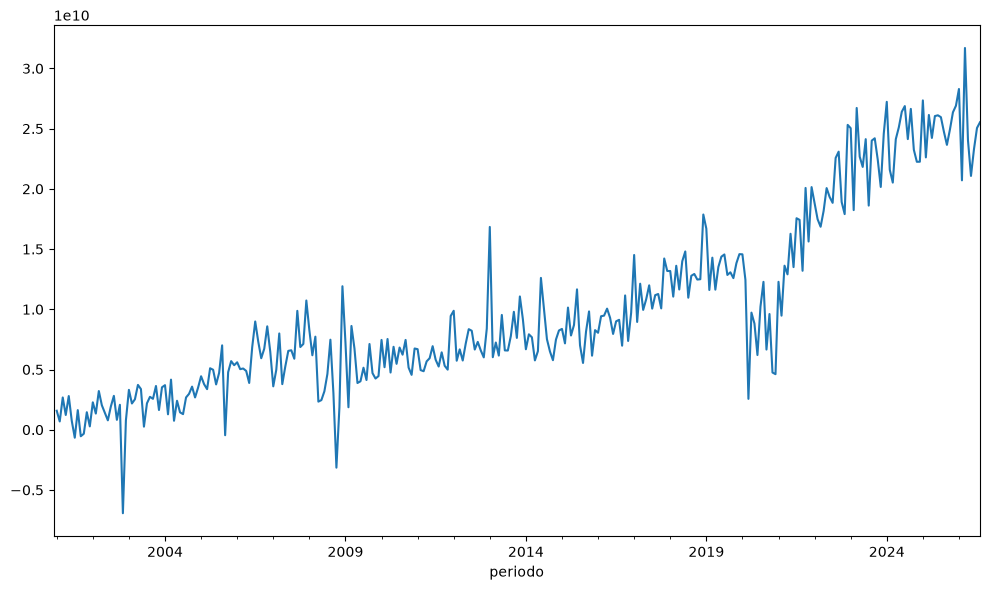

In [26]:
# Graficamos la serie temporal de 'Resultado_neto' para visualizar su evolución a lo largo del tiempo
series.loc[:,'Resultado_neto'].plot(subplots=True, figsize=(10,6))
plt.tight_layout()
plt.show()

## Preparación de las series y especificacion del modelo

In [ ]:
# Creamos una copia del DataFrame de series para trabajar con ella sin modificar el original
# Esto nos permite realizar transformaciones y cálculos adicionales sin afectar los datos originales
df = series.copy()


# Calculamos el crédito total sumando las distintas categorías de crédito disponibles en el DataFrame
df['Credito'] = df['Credito_comercial'] + df['Credito_consumo'] + df['Credito_vivienda']

# Calculamos el crédito real ajustado por inflación utilizando el índice de precios al consumidor (INPC)
df["Credito_real"] = (
    df["Credito"] / df["INPC"] * 100
)

# Aplicamos la transformación logarítmica a las variables monetarias para estabilizar la varianza y facilitar el análisis de tasas de crecimiento
df['Credito_real'] = df[['Credito_real']]
df['IGAE'] = df[['IGAE']].diff()
df['TC_MXN_USD'] = df[['TC_MXN_USD']].apply(np.log)

# Removemos variables que no necesitamos para el análisis posterior
df = df.drop(columns=['Reservas', 'Margen_financiero_ajustado_riesgo',
                      'INPC', 'Formacion_bruta_capital',
                      'Gastos_operativos', 'Ingresos_operativos',
                      'Comisiones_cobradas', 'Comisiones_pagadas',
                      'Activo_total',
                      'Credito', 'Credito_real',
                      'Credito_comercial',
                      'Credito_consumo',
                      'Credito_vivienda',
                      'Tasa_objetivo',
                      'Tasa_implicita',
                      'Tasa_impl_comercial',
                      'Tasa_impl_consumo',
                      'Tasa_impl_vivienda',
                      'Tasa_impl_pasiva',
                      'ROE',
                      'IMOR_comercial', 'IMOR_consumo', 'IMOR_vivienda'
                      ])

# Rellenamos con ffill
df = df.ffill()
df = df.dropna()  # Eliminamos cualquier fila que aún tenga NaN tras el ffill

# Trasndormarmos a primeras diferencias
#df = df.diff().dropna()  # Ya estamos aplicando diff en cada columna logarítmica, no es necesario hacer diff nuevamente

df.tail()

,Resultado_neto,IMOR,Margen_intermediacion,TC_MXN_USD,IGAE
periodo,,,,,
2026-04-01,2.404216e+10,2.262746,7.364420,2.857546,1.5318
2026-05-01,2.107434e+10,2.319356,7.447607,2.850901,-0.2271
2026-06-01,2.330348e+10,2.303614,7.503932,2.855430,-0.0374
2026-07-01,2.505509e+10,2.310653,7.548549,2.859955,0.8376
2026-08-01,2.552904e+10,2.293751,7.655160,2.837110,0.6023


## Estimación, análisis e interpretación de resultados

In [29]:

TARGET = "Resultado_neto"

# 1. Preparación: limpiar inf/NaN (log de valores <= 0 genera -inf/NaN)
data = df.replace([np.inf, -np.inf], np.nan).dropna()
print(f"Filas: {len(df)} -> {len(data)} tras limpiar")

y = data[TARGET]
X = data.drop(columns=[TARGET]).select_dtypes(include="number")
X = sm.add_constant(X)

# 2. Ajuste del modelo OLS
modelo = sm.OLS(y, X).fit()
print(modelo.summary())

# 3. Modelos con penalización Ridge y Lasso
# La estandarización hace comparables las escalas de las variables.
variables = X.columns.drop("const")
medias = X[variables].mean()
escalas = X[variables].std(ddof=0).replace(0, 1)

X_pen = X.copy()
X_pen[variables] = (X[variables] - medias) / escalas

# Ajusta este valor; idealmente selecciónalo mediante validación cruzada.
alpha = 0.1

# Penalizar las variables explicativas, pero no la constante.
penalizacion = np.full(X_pen.shape[1], alpha, dtype=float)
penalizacion[X_pen.columns.get_loc("const")] = 0.0

# Ridge: L1_wt=0.0; Lasso: L1_wt=1.0
modelo_ridge = sm.OLS(y, X_pen).fit_regularized(
    alpha=penalizacion,
    L1_wt=0.0,
)
modelo_lasso = sm.OLS(y, X_pen).fit_regularized(
    alpha=penalizacion,
    L1_wt=1.0,
)

def coeficientes_escala_original(modelo_regularizado):
    """Devuelve coeficientes expresados en la escala original de X."""
    params = pd.Series(modelo_regularizado.params, index=X_pen.columns)
    pendientes = params[variables] / escalas
    intercepto = params["const"] - (medias * pendientes).sum()

    return pd.concat([pd.Series({"const": intercepto}), pendientes])

coeficientes_penalizados = pd.DataFrame({
    "Ridge": coeficientes_escala_original(modelo_ridge),
    "Lasso": coeficientes_escala_original(modelo_lasso),
})

print("Coeficientes Ridge y Lasso:")
print(coeficientes_penalizados)

# 3. Multicolinealidad (VIF > 10 sugiere problema)
vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
}).query("variable != 'const'")
print(vif.sort_values("VIF", ascending=False))

# 4. Diagnósticos de residuos
resid = modelo.resid
bp = het_breuschpagan(resid, X)
jb = jarque_bera(resid)

print(f"Breusch-Pagan p-value (heterocedasticidad): {bp[1]:.4f}")
print(f"Jarque-Bera p-value (normalidad):          {jb[1]:.4f}")
print(f"Durbin-Watson (autocorrelación ~2):        {durbin_watson(resid):.4f}")

# 5. Coeficientes (sensibilidades) con errores robustos HC3 e IC 95%
robusto = modelo.get_robustcov_results(cov_type="HC3")
coefs = pd.DataFrame({
    "coef": modelo.params,
    "std_err_HC3": robusto.bse,
    "p_value_HC3": robusto.pvalues,
}, index=X.columns)


coefs[["IC_inf", "IC_sup"]] = np.asarray(robusto.conf_int())
print(coefs)

Filas: 308 -> 308 tras limpiar
                            OLS Regression Results                            
Dep. Variable:         Resultado_neto   R-squared:                       0.583
Model:                            OLS   Adj. R-squared:                  0.578
Method:                 Least Squares   F-statistic:                     106.0
Date:              mié., 18 nov. 2026   Prob (F-statistic):           2.29e-56
Time:                        11:19:36   Log-Likelihood:                -7305.4
No. Observations:                 308   AIC:                         1.462e+04
Df Residuals:                     303   BIC:                         1.464e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------